# B5 — Huấn luyện Vòng 2 (Run 2 trên tập `combined_round1.csv`)

**Mục tiêu của Bước 5 (B5):**
1. Khởi tạo lại từng mô hình từ **pretrained gốc ở chuẩn `FP32` master weights** (tránh *confirmation bias* từ Run 1 và đảm bảo **cả 7/7 mô hình kể cả `ViDeBERTa-base`** hội tụ mượt mà trên Transformers v5.24).
2. Huấn luyện trên tập dữ liệu đã mở rộng & cân bằng lớp từ Bước B4 (`pseudo_round1/combined_round1.csv` — `34.404` mẫu, giảm $IR$ từ `2.29` → `1.61`).
3. Chọn best checkpoint theo `eval_f1_macro` trên `val.csv` (`2.737` mẫu cố định), chấm điểm độc lập trên `test_clean.csv` (`3.000` mẫu khóa kín).
4. **Biểu đồ xuất tại `workspace_outputs/figures/B5_run2/` (300 DPI `.png` + `.pdf`):**
   - `B5_01_learning_curves_run2`: Learning Curves (Train/Val Loss & Val Macro-F1) của các mô hình ở Vòng 2.
   - `B5_02_buoc_nhay_run1_sang_run2`: Biểu đồ Dumbbell so sánh bước nhảy `Δ Macro-F1` & `Δ Accuracy` từ Run 1 → Run 2.

In [1]:
# Bước 5.1: Khởi tạo môi trường, công tắc linh hoạt & kiểm tra tập dữ liệu Combined Vòng 1
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    PipelineConfig,
    ensure_directories,
    set_global_seed,
    get_figure_dir,
    PROCESSED_DATA_DIR,
    PSEUDO_ROUND1_DIR,
    CHECKPOINTS_DIR,
    METRICS_DIR,
    LABEL_NAMES,
)
from src.trainer import ESGTrainer
from src.evaluator import ESGEvaluator
from src.viz_utils import (
    plot_learning_curves_grid,
    plot_run_delta_comparison,
)

ensure_directories()

# ==================== CÔNG TẮC LINH HOẠT CHO BƯỚC B5 ====================
# - hardware_mode : 'eco' | 'balanced' (mặc định RTX 5070) | 'performance'
# - model_preset  : 'fast_3' | 'vietnamese_4' | 'full_7'
# - skip_if_done  : True -> an toàn chạy tiếp nếu tạm ngắt giữa chừng
cfg = PipelineConfig(
    hardware_mode="balanced",
    model_preset="full_7",
    skip_if_done=True,
)
# ========================================================================

set_global_seed(cfg.seed)
FIG_DIR = get_figure_dir("B5")

print(cfg.summary())
print(f"\nNơi lưu biểu đồ Bước B5: {FIG_DIR}")

W1122 21:27:19.405000 25328 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


=== CẤU HÌNH HỆ THỐNG VI-ESG-BERT ===
- Chế độ phần cứng : balanced (train_bs=16 x accum=2, bf16=True, grad_ckpt=False, nghỉ=15s)
- Gói mô hình      : full_7 (7 mô hình: phobert-base, distilbert-base-multilingual-cased, bert-base-multilingual-cased, roberta-base, electra-base-vn, visobert, videberta-base)
- Ablation Baseline: bật=True | gói=fast_3 (electra-base-vn, phobert-base, visobert)
- Công tắc an toàn : skip_if_done=True | seed=42
- Siêu tham số     : max_length=256 | lr=2e-05 | warmup=0.1 | metric=f1_macro
- Pseudo & Cân bằng: R1(conf>=0.94, margin>=0.5, target=9,500/lớp) | R2(conf>=0.91, target=10,500/lớp)
- Thư mục biểu đồ  : D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures (DPI=300, PDF=True)

Nơi lưu biểu đồ Bước B5: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B5_run2


In [2]:
# Bước 5.2: Nạp combined_round1.csv, val.csv và test_clean.csv
combined_r1_path = PSEUDO_ROUND1_DIR / "combined_round1.csv"
assert combined_r1_path.exists(), f"Chưa thấy {combined_r1_path} — hãy chạy Bước B4 trước!"

combined_r1_df = pd.read_csv(combined_r1_path)
val_df = pd.read_csv(PROCESSED_DATA_DIR / "val.csv")
test_df = pd.read_csv(PROCESSED_DATA_DIR / "test_clean.csv")

print(f"- combined_round1.csv : {len(combined_r1_df):,} mẫu | Phân bố lớp: {combined_r1_df['labels'].value_counts().sort_index().to_dict()}")
print(f"- val.csv             : {len(val_df):,} mẫu (Validation cố định)")
print(f"- test_clean.csv      : {len(test_df):,} mẫu (Hold-out Test khóa kín)")

trainer = ESGTrainer(cfg)
evaluator = ESGEvaluator(LABEL_NAMES)

- combined_round1.csv : 34,404 mẫu | Phân bố lớp: {0: 5904, 1: 9500, 2: 9500, 3: 9500}
- val.csv             : 2,737 mẫu (Validation cố định)
- test_clean.csv      : 3,000 mẫu (Hold-out Test khóa kín)


In [3]:
# Bước 5.3: Huấn luyện Run 2 cho tất cả mô hình trong cfg.get_active_models()
run2_train_summaries = {}
run2_test_results = {}

active_models = cfg.get_active_models()
print(f"Bắt đầu huấn luyện Run 2 cho {len(active_models)} mô hình trên combined_round1.csv ({len(combined_r1_df):,} mẫu)...")

for spec in active_models:
    ckpt_dir = CHECKPOINTS_DIR / "run2" / spec.short_name
    train_summary = trainer.train_single_model(
        model_spec=spec,
        train_df=combined_r1_df,
        val_df=val_df,
        run_tag="run2",
        num_epochs=cfg.num_epochs_run2,
        checkpoint_dir=ckpt_dir,
        data_source_label="combined_round1.csv (Original + Pseudo R1)",
    )
    run2_train_summaries[spec.short_name] = train_summary

    # Chấm điểm độc lập trên Hold-out Test Set
    eval_res = evaluator.evaluate_checkpoint(
        model_spec=spec,
        checkpoint_dir=ckpt_dir,
        test_df=test_df,
        config=cfg,
        run_tag="run2",
    )
    run2_test_results[spec.short_name] = eval_res

Bắt đầu huấn luyện Run 2 cho 7 mô hình trên combined_round1.csv (34,404 mẫu)...
[Bỏ qua Train] [run2] PhoBERT-base đã hoàn tất trước đó -> nạp lại tóm tắt từ run2_phobert-base_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho run2 / PhoBERT-base -> nạp lại từ đĩa.
[Bỏ qua Train] [run2] DistilBERT-m đã hoàn tất trước đó -> nạp lại tóm tắt từ run2_distilbert-base-multilingual-cased_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho run2 / DistilBERT-m -> nạp lại từ đĩa.
[Bỏ qua Train] [run2] mBERT-cased đã hoàn tất trước đó -> nạp lại tóm tắt từ run2_bert-base-multilingual-cased_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho run2 / mBERT-cased -> nạp lại từ đĩa.
[Bỏ qua Train] [run2] RoBERTa-base đã hoàn tất trước đó -> nạp lại tóm tắt từ run2_roberta-base_train_summary.json
[Bỏ qua Eval] Đã có kết quả test cho run2 / RoBERTa-base -> nạp lại từ đĩa.
[Bỏ qua Train] [run2] Vi-ELECTRA đã hoàn tất trước đó -> nạp lại tóm tắt từ run2_electra-base-vn_train_summary.json
[Bỏ 

{'loss': '4.618', 'grad_norm': '20.67', 'learning_rate': '1.459e-05', 'epoch': '1'}
  [ViDeBERTa-base] Epoch 1/8 | Train Loss=4.6180 | Val Loss=0.9247 | Val Macro-F1=62.24% | Val Acc=63.35%
{'eval_loss': '0.9247', 'eval_accuracy': '0.6335', 'eval_f1_macro': '0.6224', 'eval_f1_micro': '0.6335', 'eval_f1_weighted': '0.6294', 'eval_precision_macro': '0.6318', 'eval_precision_weighted': '0.6406', 'eval_recall_macro': '0.6323', 'eval_recall_weighted': '0.6335', 'eval_runtime': '3.387', 'eval_samples_per_second': '808.2', 'eval_steps_per_second': '50.79', 'epoch': '1'}
{'loss': '2.307', 'grad_norm': '32.25', 'learning_rate': '1.25e-05', 'epoch': '2'}
  [ViDeBERTa-base] Epoch 2/8 | Train Loss=2.3073 | Val Loss=0.6088 | Val Macro-F1=77.11% | Val Acc=77.42%
{'eval_loss': '0.6088', 'eval_accuracy': '0.7742', 'eval_f1_macro': '0.7711', 'eval_f1_micro': '0.7742', 'eval_f1_weighted': '0.775', 'eval_precision_macro': '0.7817', 'eval_precision_weighted': '0.7836', 'eval_recall_macro': '0.7679', 'eval

Đánh giá Test [run2] ViDeBERTa-base: 100%|██████████| 94/94 [00:02<00:00, 40.82batch/s]


  => [run2] ViDeBERTa-base  | Acc=84.90% | Macro-F1=83.75% | Weighted-F1=84.55% | ECE=0.0853 | Tốc độ=1241.1 mẫu/s


In [4]:
# Bước 5.4: Tổng hợp bảng điểm Run 2 & tính bước nhảy so với Run 1 và Baseline
rows = []
for short_name, eval_res in run2_test_results.items():
    ov = eval_res["overall_metrics"]
    pc = eval_res["per_class_metrics"]
    tr = run2_train_summaries.get(short_name, {})
    val_f1 = tr.get("best_val_metrics", {}).get("eval_f1_macro", 0.0)
    rows.append({
        "run_tag": "run2",
        "model_short_name": short_name,
        "model_display_name": eval_res["model_display_name"],
        "best_epoch": tr.get("best_epoch", None),
        "val_f1_macro_pct": round(val_f1 * 100.0, 2),
        "accuracy_pct": round(ov["accuracy"] * 100.0, 2),
        "f1_macro_pct": round(ov["f1_macro"] * 100.0, 2),
        "f1_weighted_pct": round(ov["f1_weighted"] * 100.0, 2),
        "f1_irrelevant_pct": round(pc["Irrelevant"]["f1-score"] * 100.0, 2),
        "f1_environment_pct": round(pc["Environment"]["f1-score"] * 100.0, 2),
        "f1_social_pct": round(pc["Social"]["f1-score"] * 100.0, 2),
        "f1_governance_pct": round(pc["Governance"]["f1-score"] * 100.0, 2),
        "ece": round(ov["ece"], 4),
        "peak_vram_gb": tr.get("peak_vram_gb", None),
        "train_minutes": round(tr.get("train_seconds", 0.0) / 60.0, 2),
    })

b5_summary_df = pd.DataFrame(rows).sort_values("f1_macro_pct", ascending=False).reset_index(drop=True)
summary_csv = METRICS_DIR / "B5_run2_summary.csv"
b5_summary_df.to_csv(summary_csv, index=False, encoding="utf-8-sig")
print(f"[Đã lưu bảng tổng hợp Run 2] {summary_csv}")
display(b5_summary_df)

# So sánh trực tiếp Delta Run 1 -> Run 2
b3_csv = METRICS_DIR / "B3_baseline_and_run1_summary.csv"
if b3_csv.exists():
    b3_df = pd.read_csv(b3_csv)
    r1_df = b3_df[b3_df["run_tag"] == "run1"][["model_display_name", "accuracy_pct", "f1_macro_pct", "f1_irrelevant_pct"]]
    cmp_df = pd.merge(r1_df, b5_summary_df[["model_display_name", "accuracy_pct", "f1_macro_pct", "f1_irrelevant_pct"]], on="model_display_name", suffixes=("_r1", "_r2"))
    cmp_df["delta_acc"] = (cmp_df["accuracy_pct_r2"] - cmp_df["accuracy_pct_r1"]).round(2)
    cmp_df["delta_f1_macro"] = (cmp_df["f1_macro_pct_r2"] - cmp_df["f1_macro_pct_r1"]).round(2)
    cmp_df["delta_f1_irrelevant"] = (cmp_df["f1_irrelevant_pct_r2"] - cmp_df["f1_irrelevant_pct_r1"]).round(2)
    print("\n=== BƯỚC NHẢY HIỆU NĂNG: RUN 1 -> RUN 2 ===")
    display(cmp_df.sort_values("f1_macro_pct_r2", ascending=False))

[Đã lưu bảng tổng hợp Run 2] D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\metrics\B5_run2_summary.csv


,run_tag,model_short_name,model_display_name,best_epoch,val_f1_macro_pct,accuracy_pct,f1_macro_pct,f1_weighted_pct,f1_irrelevant_pct,f1_environment_pct,f1_social_pct,f1_governance_pct,ece,peak_vram_gb,train_minutes
0,run2,bert-base-multilingual-cased,mBERT-cased,8,90.07,88.00,86.92,87.72,76.35,96.94,87.97,86.42,0.1123,4.47,24.51
1,run2,electra-base-vn,Vi-ELECTRA,3,90.93,87.77,86.79,87.59,76.29,97.65,87.12,86.12,0.0911,3.82,6.83
2,run2,phobert-base,PhoBERT-base,3,89.78,87.27,85.89,86.96,71.89,97.40,88.93,85.33,0.0881,3.84,6.54
3,run2,distilbert-base-multilingual-cased,DistilBERT-m,5,88.86,87.10,85.80,86.71,73.47,96.27,87.37,86.10,0.1029,2.96,6.28
4,run2,visobert,ViSoBERT,7,87.22,85.77,84.98,85.55,76.70,94.74,82.85,85.64,0.1295,3.30,13.17
5,run2,roberta-base,RoBERTa-base,8,84.88,86.00,84.49,85.49,71.26,94.46,87.76,84.49,0.1015,3.70,18.95
6,run2,videberta-base,ViDeBERTa-base,7,84.03,84.90,83.75,84.55,72.62,93.56,84.34,84.46,0.0853,3.17,87.45



=== BƯỚC NHẢY HIỆU NĂNG: RUN 1 -> RUN 2 ===


,model_display_name,accuracy_pct_r1,f1_macro_pct_r1,f1_irrelevant_pct_r1,accuracy_pct_r2,f1_macro_pct_r2,f1_irrelevant_pct_r2,delta_acc,delta_f1_macro,delta_f1_irrelevant
2,mBERT-cased,87.60,86.06,71.89,88.00,86.92,76.35,0.40,0.86,4.46
4,Vi-ELECTRA,88.03,87.29,77.49,87.77,86.79,76.29,-0.26,-0.50,-1.20
0,PhoBERT-base,87.67,86.43,73.43,87.27,85.89,71.89,-0.40,-0.54,-1.54
1,DistilBERT-m,85.37,83.86,70.20,87.10,85.80,73.47,1.73,1.94,3.27
5,ViSoBERT,82.90,80.37,60.54,85.77,84.98,76.70,2.87,4.61,16.16
3,RoBERTa-base,81.33,79.28,61.52,86.00,84.49,71.26,4.67,5.21,9.74
6,ViDeBERTa-base,28.33,11.04,0.00,84.90,83.75,72.62,56.57,72.71,72.62


[Đã lưu biểu đồ] B5_01_learning_curves_run2.png, B5_01_learning_curves_run2.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B5_run2


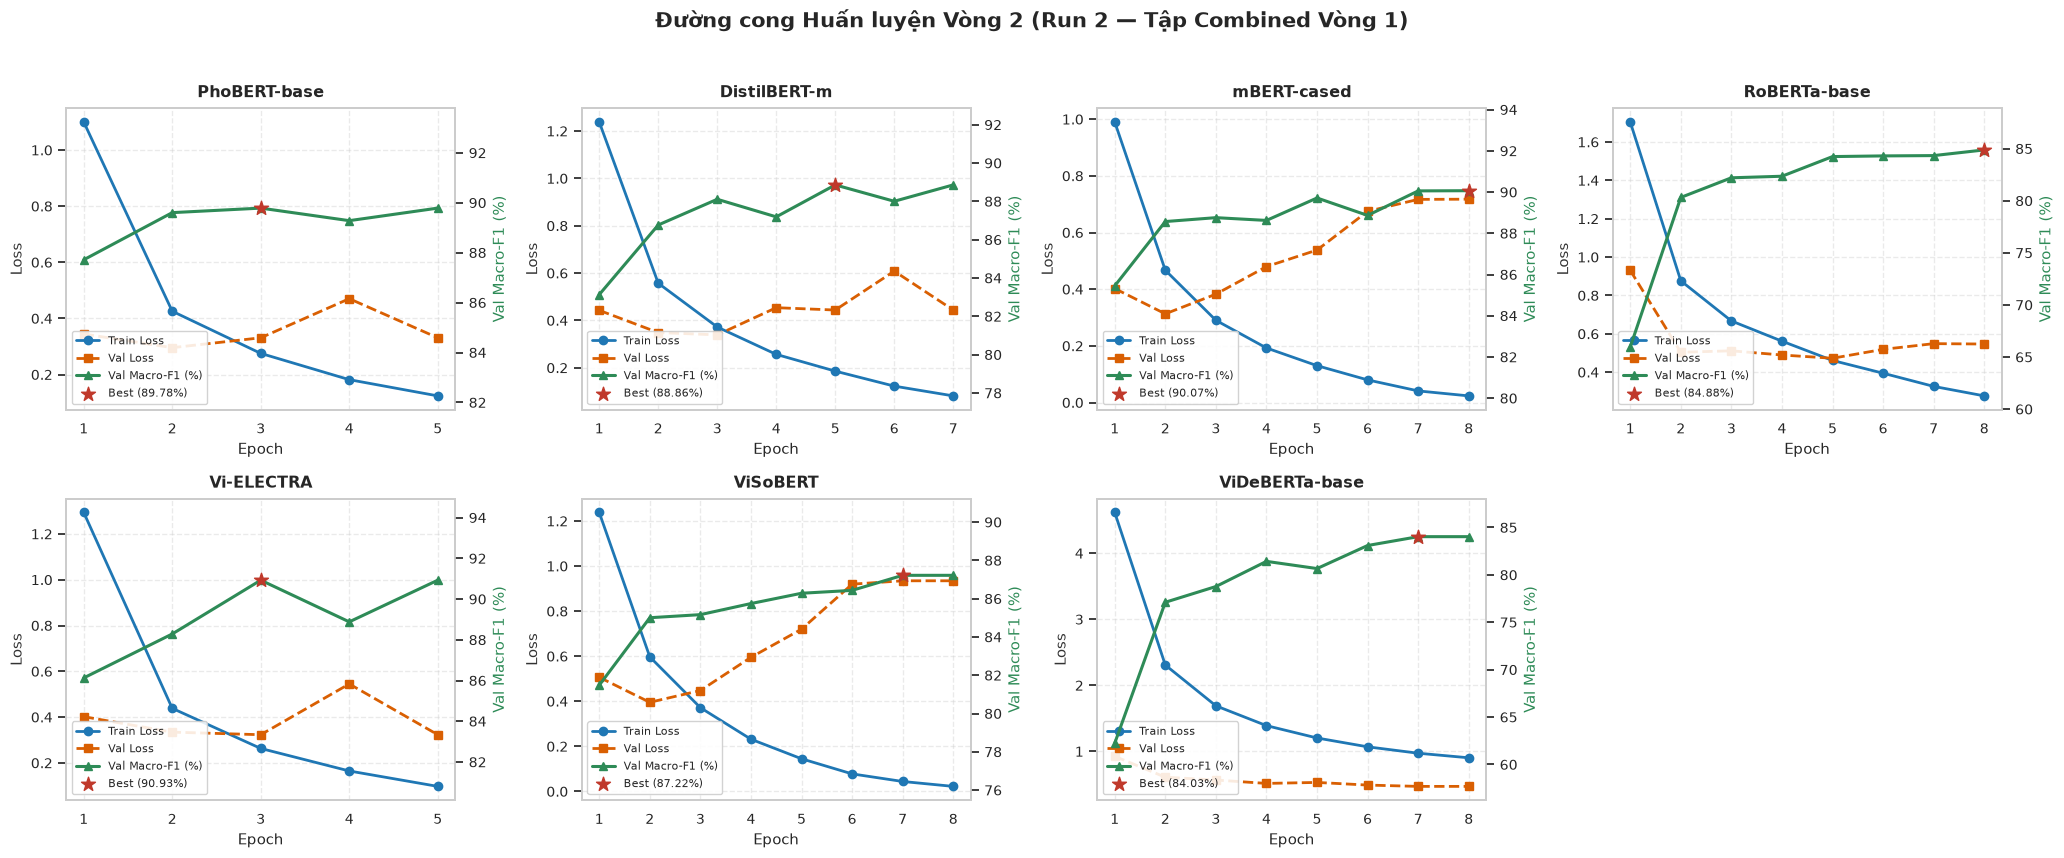

[Đã lưu biểu đồ] B5_02_buoc_nhay_run1_sang_run2.png, B5_02_buoc_nhay_run1_sang_run2.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B5_run2


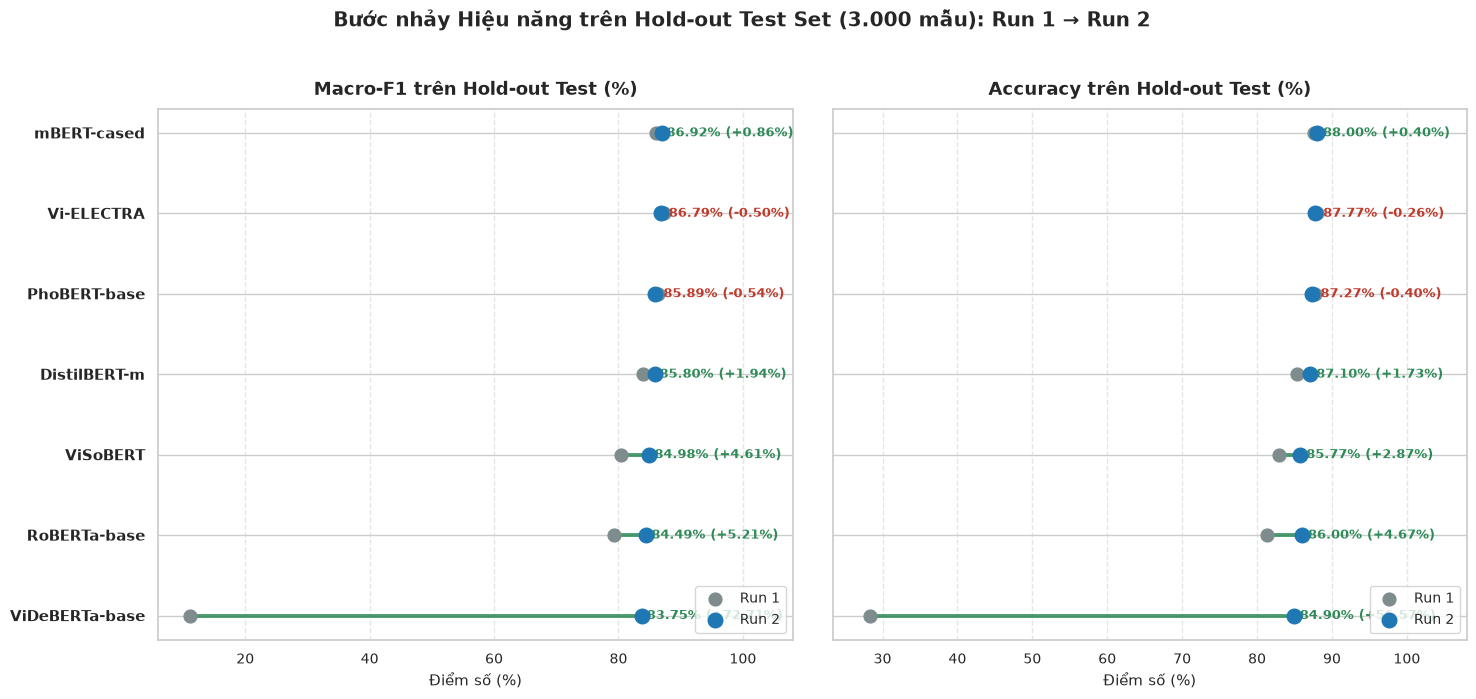


=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B5_run2 ===
  - B5_01_learning_curves_run2.pdf
  - B5_01_learning_curves_run2.png
  - B5_02_buoc_nhay_run1_sang_run2.pdf
  - B5_02_buoc_nhay_run1_sang_run2.png


In [5]:
# Bước 5.5 — Biểu đồ B5.1 (Learning Curves Vòng 2) & B5.2 (Bước nhảy Run 1 -> Run 2)
run2_histories = {}
for spec in cfg.get_active_models():
    hist_path = METRICS_DIR / f"run2_{spec.short_name}_history.csv"
    if hist_path.exists():
        run2_histories[spec.display_name] = pd.read_csv(hist_path)

if run2_histories:
    fig_lc_r2 = plot_learning_curves_grid(
        histories=run2_histories,
        title="Đường cong Huấn luyện Vòng 2 (Run 2 — Tập Combined Vòng 1)",
        save_dir=FIG_DIR,
        filename_stem="B5_01_learning_curves_run2",
        dpi=cfg.figure_dpi,
        save_pdf=cfg.save_pdf_figures,
    )
    plt.show()

if b3_csv.exists():
    b3_df = pd.read_csv(b3_csv)
    run1_only = b3_df[b3_df["run_tag"] == "run1"]
    fig_delta = plot_run_delta_comparison(
        run1_df=run1_only,
        run2_df=b5_summary_df,
        title="Bước nhảy Hiệu năng trên Hold-out Test Set (3.000 mẫu): Run 1 → Run 2",
        save_dir=FIG_DIR,
        filename_stem="B5_02_buoc_nhay_run1_sang_run2",
        dpi=cfg.figure_dpi,
        save_pdf=cfg.save_pdf_figures,
    )
    plt.show()

print("\n=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B5_run2 ===")
for p in sorted(FIG_DIR.glob("*")):
    print(f"  - {p.name}")